In [1]:
# ====================================
# Import libraries
# ====================================
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import random_split, DataLoader
import torchvision.transforms.v2 as T
from torch.utils.data import TensorDataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

"""
This code combines `task2_Class`, `task2_Regress` and `task2_MultiHead` and
runs them on the **150x150** images. As the assignment suggested, the models were
prototyped on the 75x75 images, then the results will be reported on the 150x150 images.
For this reason, and to save computational time, here we train only the best setting for
each approach which was chosen using the validation error of the 75x75 notebooks.
"""

'\nThis code combines `task2_Class`, `task2_Regress` and `task2_MultiHead` and \nruns them on the **150x150** images. As the assignment suggested, the models were \nprototyped on the 75x75 images, then the results will be reported on the 150x150 images.\nFor this reason, and to save computational time, here we train only the best setting for\neach approach which was chosen using the validation error of the 75x75 notebooks. \n'

In [2]:
#Check whether a GPU is available
print("GPU available:", torch.cuda.is_available())

#Check which GPU is being used
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

GPU available: True
GPU name: Tesla T4


In [3]:
# ====================================
# Reproducibility and device
# ====================================
r_seed = 99
generator = torch.Generator()

def reset_seed(seed=r_seed):
    """Reset all seeds at once."""
    random.seed(seed) #reset python random seed
    np.random.seed(seed) #reset numpy random seed
    torch.manual_seed(seed) #reset pytorch random seed
    generator.manual_seed(seed) #reset the dataloader random seed
    if torch.cuda.is_available(): #if we use the gpu
        torch.cuda.manual_seed_all(seed)

reset_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
# =====================================
# Settings for the final runs
# =====================================

#Settings chosen after task2_CNN_Selection
epochs = 40 #here we use 40 epochs (compared to the 20 for the 75x75, because the task is harder)
learning_rate = 0.001

final_rows = []

In [5]:
#This cell runs on Google Colab if you save the data files in a folder called "data" in Drive.
#To run locally, skip this cell and set the paths to data/075_images.npy

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# ====================================
# Load the Clock dataset (150x150)
# ====================================
images_path = '/content/drive/MyDrive/DL_Assignment_1/data/150_images.npy'
labels_path = '/content/drive/MyDrive/DL_Assignment_1/data/150_labels.npy'

images_np = np.load(images_path)
labels_np = np.load(labels_path)

#Check out our images
print("images:", images_np.shape, images_np.dtype, images_np.min(), images_np.max()) #18'000 images, 150x150
print("labels:", labels_np.shape, labels_np.dtype) #18'000 labels, 2 dimensions (hour, min)
print("hours:", np.unique(labels_np[:, 0])) #they go from 0 to 11
print("minutes:", labels_np[:, 1].min(), labels_np[:, 1].max()) #they go from 0 to 59

#Convert into pytorch tensors
images = torch.from_numpy(images_np).float() #turn numpy array into pytorch tensor, float
images = images.unsqueeze(1) #add channel dimension, we need format (batch_size, channels, height, width) (greyscale = 1 channel)
del images_np
mean = images.mean()
std = images.std()
images -= mean #we do it in place to save memory
images /= std

#Labels: here we just save them as pytorch tensors, but we keep them like this because each approach needs a different formulation
labels_hour = torch.from_numpy(labels_np[:, 0]).long()   #hours, 0-11
labels_minute = torch.from_numpy(labels_np[:, 1]).long() #minutes, 0-59
print(labels_hour.shape, labels_minute.shape) #18'000 labels for both

images: (18000, 150, 150) uint8 0 255
labels: (18000, 2) int64
hours: [ 0  1  2  3  4  5  6  7  8  9 10 11]
minutes: 0 59
torch.Size([18000]) torch.Size([18000])


In [7]:
#=====================================
# Train-Validation-Test split
# ====================================
reset_seed()

dataset = TensorDataset(images, labels_hour, labels_minute)
n = len(dataset)

train_size = int(0.8 * n)
valid_size = int(0.1 * n)
test_size = n - train_size - valid_size

train_data, valid_data, test_data = random_split(
    dataset,
    [train_size, valid_size, test_size],
    generator=generator
)

batch_size = 64

train_dataloader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

valid_dataloader = DataLoader(
    valid_data,
    batch_size=batch_size,
    shuffle=True
)

test_dataloader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=True
)

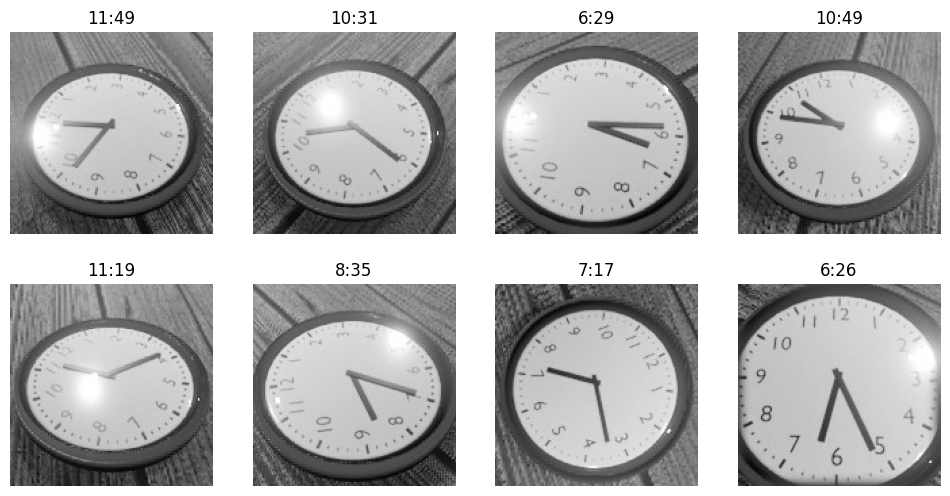

In [8]:
#=====================================
# Trying to see images (higher resolution)
# ====================================
images_batch, hours_batch, minutes_batch = next(iter(train_dataloader))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, h, m in zip(axes.flat, images_batch, hours_batch, minutes_batch):
    ax.imshow(img[0]*std + mean, cmap="gray")
    ax.set_title(f"{h.item()}:{m.item():02d}")
    ax.axis("off")
plt.show()

In [9]:
# =====================================
# Setting up the CNNs
# =====================================

#We use the same final CNN (4 conv blocks) for all three approaches,
#only the output layer changes

class Net_4conv(nn.Module):   #Final CNN
    def __init__(self, num_outputs):
        super().__init__()
        #Input image (1, 150, 150) (greyscale)
        self.conv1 = nn.Conv2d(1, 6, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv4 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 9 * 9, 120)
        self.fc2 = nn.Linear(120, num_outputs)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.pool(F.relu(self.conv4(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x


class Net_4conv_MultiHead(nn.Module): #Final CNN for Multi Head (12 classes for hours, 60 classes for minutes)
    def __init__(self):
        super().__init__()
        #Same layers for both heads
        self.conv1 = nn.Conv2d(1, 6, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv4 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 9 * 9, 120)
        #Two separate outputs
        self.hour_head = nn.Linear(120, 12) #head 1: hour
        self.minute_head = nn.Linear(120, 60) #head 2: minute

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.pool(F.relu(self.conv4(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        #two separate outputs
        return self.hour_head(x), self.minute_head(x)


In [10]:
# ======================================================
# Functions for training and evaluation: CLASSIFICATION
# ======================================================

#We need two different train_model() and validate() model functions for each approach

#Functions for training and evaluation: CLASSIFICATION

#Train the model
def train_classification(model, train_dataloader, optimizer, criterion, epochs, bin_size):

    """Train a classification model for a given number of epochs."""

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for inputs, hours, minutes in train_dataloader:

            #data agumentation
            #inputs = train_transform(inputs)

            #To use external GPU
            inputs = inputs.to(device)
            hours = hours.to(device)
            minutes = minutes.to(device)

            #total minutes since 00:00 (e.g., 01:30 --> 90 minutes) (before we computed it in the loading chunk)
            total_minutes = hours * 60 + minutes

            #convert the labels from labels in minutes to labels in classes (e.g., class 3)
            labels_class = (total_minutes // bin_size).long()

            #zero the parameter gradients
            optimizer.zero_grad()

            #forward + backward + optimize
            outputs = model(inputs) #predictions
            loss = criterion(outputs, labels_class) #compute loss
            loss.backward() #compute gradients
            optimizer.step() #optimize weights

            #compute running loss
            running_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"- Loss = {running_loss/len(train_dataloader):.4f}"
        )

#Validate the model
def evaluate_classification(model, dataloader, bin_size):

    """Evaluate a classification model using the average circular time error."""

    model.eval()
    total_error = 0
    total = 0

    with torch.no_grad():
        for inputs, hours, minutes in dataloader:

            #To use external GPU
            inputs = inputs.to(device)
            hours = hours.to(device)
            minutes = minutes.to(device)
            true_minutes = hours * 60 + minutes

            #Get predictions and classes
            outputs = model(inputs) #predictions (in classes!!!)
            predictions = outputs.argmax(dim=1) #assign to the class with the highest score

            #Convert predicted classes back into total minutes
            predicted_minutes = predictions * bin_size + (bin_size - 1) / 2 #midpoint to represent the class

            #Calculate absolute difference and the circular difference
            difference = torch.abs(predicted_minutes - true_minutes)
            circular_difference = torch.minimum(difference, 720 - difference)

            #Compute the errors
            total_error += circular_difference.sum().item()
            total += minutes.size(0)

    common_sense_error = total_error / total
    return common_sense_error


#Functions for training and evaluation: REGRESSION

#Train the model
def train_regression(model, train_dataloader, optimizer, criterion, epochs):

    """Train a regression model for a given number of epochs."""

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for inputs, hours, minutes in train_dataloader:

            #To use external GPU
            inputs = inputs.to(device)
            hours = hours.to(device)
            minutes = minutes.to(device)

            #the time as a number of hours (e.g., 03:30 --> 3.5) (we compute it here!)
            target = (hours + minutes / 60.0).float()

            #zero the parameter gradients
            optimizer.zero_grad()

            #forward + backward + optimize
            outputs = model(inputs).squeeze(1) #predictions (one number per image)
            loss = criterion(outputs, target) #regression loss
            loss.backward() #compute gradients
            optimizer.step() #optimize weights

            #compute running loss
            running_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"- Loss = {running_loss/len(train_dataloader):.4f}"
        )

#Validate / test the model
def evaluate_regression(model, dataloader):

    """Evaluate a regression model using the average circular time error."""

    model.eval()
    total_error = 0
    total = 0

    with torch.no_grad():
        for inputs, hours, minutes in dataloader:
            #To use external GPU
            inputs = inputs.to(device)
            hours = hours.to(device)
            minutes = minutes.to(device)
            true_minutes = (hours * 60 + minutes).float()

            #Get predictions (in hours, e.g. 3.5)
            outputs = model(inputs).squeeze(1)
            predicted_hours = torch.remainder(outputs, 12.0) #restrict prediction in 12 hours range

            #Calculate absolute difference and the circular difference (in minutes!!)
            predicted_minutes = predicted_hours * 60.0 #We re-convert them in minutes to make it comparable with the other models
            difference = torch.abs(predicted_minutes - true_minutes)
            circular_difference = torch.minimum(difference, 720 - difference)

            #Compute the errors
            total_error += circular_difference.sum().item()
            total += minutes.size(0)

    common_sense_error = total_error / total
    return common_sense_error


#Functions for training and evaluation: MULTI-HEAD

#Train the model
def train_multihead(model, train_dataloader, optimizer, criterion, epochs, alpha): #alpha for combining the losses
    """Train a multi-head model for a given number of epochs."""
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for inputs, hours, minutes in train_dataloader:

            #data agumentation
            #inputs = train_transform(inputs)

            #To use external GPU
            inputs = inputs.to(device)
            minutes = minutes.to(device)
            hours = hours.to(device)

            #zero the parameter gradients
            optimizer.zero_grad()

            #forward + backward + optimize
            out_hour, out_minute = model(inputs) #predictions
            loss_hour = criterion(out_hour, hours) #Loss for HOURS
            loss_minute = criterion(out_minute, minutes) #Loss for MINUTES
            loss = loss_hour + alpha * loss_minute #COMBINE the Losses
            loss.backward() #compute gradients
            optimizer.step() #optimize weights

            #compute running loss
            running_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"- Loss = {running_loss/len(train_dataloader):.4f}"
        )

#Validate / test the model
def evaluate_multihead(model, dataloader):

    """Evaluate a multi-head model using the average circular time error."""

    model.eval()
    total_error = 0
    total = 0

    with torch.no_grad():
        for inputs, hours, minutes in dataloader:

            #To use external GPU
            inputs = inputs.to(device)
            minutes = minutes.to(device)
            hours = hours.to(device)

            #Get predictions and classes
            out_hour, out_minute = model(inputs) #predictions
            predicted_hours = torch.argmax(out_hour, dim=1) #Class for HOURS: assign to the class with the highest score
            predicted_minutes = torch.argmax(out_minute, dim=1) #Class for MINUTES: assign to the class with the highest score

            #Combine predictions and true times into total minutes
            predicted_time = predicted_hours * 60 + predicted_minutes #total number of minutes
            true_time = hours * 60 + minutes #total number of minutes

            #Calculate their absolute difference and their circular difference
            difference = torch.abs(predicted_time - true_time)
            circular_difference = torch.minimum(difference, 720 - difference)

            #Compute the errors
            total_error += circular_difference.sum().item()
            total += minutes.size(0)

    common_sense_error = total_error / total
    return common_sense_error

#NB.
#While we use two separate Losses to train the model (and then combine them into one),
#We use one common sense error to check how off our predictions are.
#Therefore for the common sense error we compute again the total number of minutes, and
#the circular difference, because it's convenient to estimate the error in our predictions.

In [11]:
# =====================================
# CLASSIFICATION
# =====================================

#Best settings chosen on the validation error of the 75x75 experiments
#best_bin_size = 30 #This is the bin size that got the best results on the 75x75 images
#worst_bin_size = 1 #This ensure a more fair comparison between Classification, MultiHead (using bins), and Regression
bin_sizes = [30, 1]

for bin_size in bin_sizes:

    num_classes = 720 // bin_size
    print(f"\nClassification: {bin_size}-minute bins ({num_classes} classes), {epochs} epochs")

    #New seed for every experiment
    reset_seed()

    #Create a new CNN
    model = Net_4conv(num_classes).to(device)

    #Loss function
    criterion = nn.CrossEntropyLoss()

    #Optimizer
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    #Train the model
    train_classification(model, train_dataloader, optimizer, criterion, epochs, bin_size)

    #Validation and test error
    valid_error = evaluate_classification(model, valid_dataloader, bin_size)
    test_error = evaluate_classification(model, test_dataloader, bin_size)
    print(f"Validation error: {valid_error:.2f} minutes | Test error: {test_error:.2f} minutes")

    #Save results (after every run, so nothing is lost if the session stops)
    final_rows.append({
        "Formulation": "Classification",
        "Setting": f"{bin_size}-minute bins",
        "Epochs": epochs,
        "Validation error (min)": valid_error,
        "Test error (min)": test_error
    })


# =====================================
# REGRESSION
# =====================================

#Best settings chosen on the validation error of the 75x75 experiments
loss_functions = {"MSELoss": nn.MSELoss(), "L1Loss": nn.L1Loss(), "SmoothL1Loss": nn.SmoothL1Loss()}
best_loss = "SmoothL1Loss"
criterion = loss_functions[best_loss] #SmoothL1Loss

print(f"\nRegression with {best_loss}, {epochs} epochs")

#New seed for every experiment
reset_seed()

#New model
regression_model = Net_4conv(1).to(device)

#Optimizer
optimizer = optim.Adam(regression_model.parameters(), lr=learning_rate)

#Train the model
train_regression(regression_model, train_dataloader, optimizer, criterion, epochs)

#Validation and test error
valid_error = evaluate_regression(regression_model, valid_dataloader)
test_error = evaluate_regression(regression_model, test_dataloader)
print(f"Validation error: {valid_error:.2f} minutes | Test error: {test_error:.2f} minutes")

#Save results
final_rows.append({
    "Formulation": "Regression",
    "Setting": best_loss,
    "Epochs": epochs,
    "Validation error (min)": valid_error,
    "Test error (min)": test_error
})


# =====================================
# MULTI-HEAD
# =====================================

#Best settings chosen on the validation error of the 75x75 experiments
best_alpha = 0.5
print(f"\nMulti-head with alpha = {best_alpha}, {epochs} epochs")

#New seed for every experiment
reset_seed()

#New model
multihead_model = Net_4conv_MultiHead().to(device)

#Loss function
criterion = nn.CrossEntropyLoss()

#Optimizer
optimizer = optim.Adam(multihead_model.parameters(), lr=learning_rate)

#Train the model
train_multihead(multihead_model, train_dataloader, optimizer, criterion, epochs, best_alpha)

#Validation and test error
valid_error = evaluate_multihead(multihead_model, valid_dataloader)
test_error = evaluate_multihead(multihead_model, test_dataloader)
print(f"Validation error: {valid_error:.2f} minutes | Test error: {test_error:.2f} minutes")

#Save results
final_rows.append({
    "Formulation": "Multi-head",
    "Setting": f"alpha = {best_alpha}",
    "Epochs": epochs,
    "Validation error (min)": valid_error,
    "Test error (min)": test_error
})


Classification: 30-minute bins (24 classes), 40 epochs
Epoch 1/40: - Loss = 3.1796
Epoch 2/40: - Loss = 3.1786
Epoch 3/40: - Loss = 3.1785
Epoch 4/40: - Loss = 3.1784
Epoch 5/40: - Loss = 3.1783
Epoch 6/40: - Loss = 3.1783
Epoch 7/40: - Loss = 3.1783
Epoch 8/40: - Loss = 3.1786
Epoch 9/40: - Loss = 3.1783
Epoch 10/40: - Loss = 3.1163
Epoch 11/40: - Loss = 2.4553
Epoch 12/40: - Loss = 2.0417
Epoch 13/40: - Loss = 1.8311
Epoch 14/40: - Loss = 1.6679
Epoch 15/40: - Loss = 1.5333
Epoch 16/40: - Loss = 1.4121
Epoch 17/40: - Loss = 1.3040
Epoch 18/40: - Loss = 1.2089
Epoch 19/40: - Loss = 1.1222
Epoch 20/40: - Loss = 1.0342
Epoch 21/40: - Loss = 0.9649
Epoch 22/40: - Loss = 0.9145
Epoch 23/40: - Loss = 0.8512
Epoch 24/40: - Loss = 0.7869
Epoch 25/40: - Loss = 0.7574
Epoch 26/40: - Loss = 0.7076
Epoch 27/40: - Loss = 0.6661
Epoch 28/40: - Loss = 0.6252
Epoch 29/40: - Loss = 0.5898
Epoch 30/40: - Loss = 0.5540
Epoch 31/40: - Loss = 0.5286
Epoch 32/40: - Loss = 0.4896
Epoch 33/40: - Loss = 0.4

In [12]:
# ====================================
# Compare performances (150x150)
# ====================================
#Compare the performance of:
# - Multi Head (separate min and hour)
# - Classification (together min and hour)
# - Regression (together min and hour)
#All three use the same CNN, optimizer, learning rate, number of epochs, split and error metric (common-sense error).

comparison = pd.DataFrame(final_rows)
print(comparison)

      Formulation         Setting  Epochs  Validation error (min)  \
0  Classification  30-minute bins      40               26.421111   
1  Classification   1-minute bins      40              132.530556   
2      Regression    SmoothL1Loss      40               47.269281   
3      Multi-head     alpha = 0.5      40              181.480000   

   Test error (min)  
0         23.555000  
1        130.395556  
2         49.251921  
3        176.730000  
